# 03. Gradient Descent và thí nghiệm tối ưu (Bước 4)

**Nhiệm vụ của notebook này:** tìm trọng số bằng Gradient Descent và thay đổi tốc độ học, chuẩn hóa để thấy ảnh hưởng (mục 2.4, 2.5).

Chạy từng ô từ trên xuống. Notebook tự đọc `data.csv` (Colab sẽ hỏi bạn tải lên; trên máy thì đặt tại `data/data.csv`).

Nên đọc theo thứ tự các notebook 01 → 06. Phần trước: 02.

In [1]:
# Ô thiết lập: cài thư viện (nếu thiếu), nạp thư viện và đọc dữ liệu
# Cài thư viện còn thiếu (tự động). Chạy được cả trên máy cá nhân lẫn Google Colab.
import importlib.util, subprocess, sys
_can = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib", "sklearn": "scikit-learn"}
_thieu = [g for m, g in _can.items() if importlib.util.find_spec(m) is None]
if _thieu:
    print("Máy chưa có:", ", ".join(_thieu), "-> đang cài, đợi một chút ...")
    if importlib.util.find_spec("pip") is None:      # môi trường ảo (venv) có thể chưa có pip
        import ensurepip; ensurepip.bootstrap()
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_thieu])
    importlib.invalidate_caches()
    print("Cài xong.")

import io, os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

warnings.filterwarnings("ignore")
SEED = 42                               # hạt giống ngẫu nhiên cố định: chạy lại ra đúng kết quả cũ
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def doc_du_lieu():
    """Tìm data.csv trên máy; nếu đang ở Colab thì xin người dùng tải lên."""
    for p in ["data/data.csv", "../data/data.csv", "../../data/data.csv", "data.csv"]:
        if os.path.exists(p):
            print("Đọc dữ liệu từ", p)
            return pd.read_csv(p, sep=";")
    try:
        from google.colab import files
        print("Hãy chọn tệp data.csv trên máy của bạn ...")
        up = files.upload()
        return pd.read_csv(io.BytesIO(list(up.values())[0]), sep=";")
    except ImportError:
        raise FileNotFoundError(f"Không thấy data.csv (thư mục hiện tại: {os.getcwd()}). Hãy đặt tệp vào thư mục data/ của dự án.")


raw = doc_du_lieu()
raw.columns = [c.strip() for c in raw.columns]      # bỏ khoảng trắng/tab thừa ở tên cột
print("Kích thước:", raw.shape)

# --- Chuẩn bị chung (lặp lại ở mỗi notebook để mỗi tệp chạy độc lập) ---
d = raw[raw.Target != "Enrolled"].reset_index(drop=True)
d["y"] = (d.Target == "Dropout").astype(int)          # 1 = bỏ học (nguy cơ), 0 = tốt nghiệp (an toàn)
ENTRY = ["Tuition fees up to date", "Debtor", "Scholarship holder", "Age at enrollment"]
YEAR1 = ["Curricular units 1st sem (approved)", "Curricular units 1st sem (grade)",
         "Curricular units 2nd sem (approved)", "Curricular units 2nd sem (grade)"]
COMPACT = ENTRY + YEAR1
ADMISSION_ONLY = ["Admission grade", "Previous qualification (grade)", "Age at enrollment",
                  "Scholarship holder", "Debtor", "Tuition fees up to date", "Gender", "Application order"]
ALL = [c for c in d.columns if c not in ("Target", "y")]
y = d.y.values
train_idx, test_idx = train_test_split(np.arange(len(d)), test_size=0.2, stratify=d.y, random_state=SEED)
ytr, yte = y[train_idx], y[test_idx]


def chuan_bi(cols, chuan_hoa=True):
    """Ma trận X cho tập huấn luyện và kiểm tra; chuẩn hóa bằng trung bình, độ lệch chuẩn của TẬP HUẤN LUYỆN."""
    X = d[cols].values.astype(float)
    Xtr, Xte = X[train_idx], X[test_idx]
    if chuan_hoa:
        mu, sd = Xtr.mean(0), Xtr.std(0); sd[sd == 0] = 1
        Xtr, Xte = (Xtr - mu) / sd, (Xte - mu) / sd
    return Xtr, Xte


def hoi_quy_sklearn(X, y):
    try:
        return LogisticRegression(penalty=None, max_iter=5000).fit(X, y)
    except Exception:
        return LogisticRegression(C=np.inf, max_iter=5000).fit(X, y)


def sigmoid(z):
    z = np.clip(z, -500, 500)
    return np.where(z >= 0, 1 / (1 + np.exp(-z)), np.exp(z) / (1 + np.exp(z)))


def cross_entropy(p, y):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))


# Dữ liệu 8 cột đã chuẩn hóa (làm ở notebook 02)
Xtr_raw, _ = chuan_bi(COMPACT, chuan_hoa=False)
Xtr, Xte = chuan_bi(COMPACT, chuan_hoa=True)


Xtr, Xte = chuan_bi(COMPACT, True)      # ma trận đã chuẩn hóa (xem notebook 02)


Đọc dữ liệu từ ../data/data.csv
Kích thước: (4424, 37)


---
# Bước 4. Gradient Descent: la bàn chỉ hướng sửa trọng số (mục 2.4 và 2.5 của đề)

## Vì sao cần bước này
Ta có thước đo mức phạt L. Giờ cần biết **chỉnh trọng số theo hướng nào để L giảm**. Hãy hình dung đứng trên sườn đồi trong sương mù, chỉ cảm nhận được độ dốc dưới chân.

## Ý chính
- **Đạo hàm riêng** của L theo một trọng số cho biết: tăng nhẹ trọng số đó thì mức phạt tăng hay giảm, và nhanh đến đâu.
- **Gradient** gom đạo hàm theo mọi trọng số lại thành một vector: một chiếc la bàn chỉ chiều *dốc lên* nhanh nhất. Muốn xuống thì đi ngược lại.
- **Quy tắc dây chuyền.** L phụ thuộc w qua một chuỗi: w → z → p → L. Đạo hàm cả chuỗi bằng tích đạo hàm từng khâu. Điều đẹp là các thừa số p(1-p) triệt tiêu nhau, để lại kết quả rất gọn:
  gradient = (1/n) · Xᵀ(p − y). Hiểu bằng lời: *trung bình của (sai số dự đoán) nhân (giá trị chỉ số)*.
- **Gradient Descent:** w ← w − η · gradient. Số η là **tốc độ học**, độ dài mỗi bước. Quá nhỏ thì đi mãi không tới đáy; quá lớn thì nhảy qua đáy, càng nhảy càng cao, thậm chí phân kỳ.
- Với Hồi quy Logistic, L là hàm **lồi**: chỉ có một đáy. Đi xuống từ đâu cũng tới cùng một nơi.

In [2]:
def huan_luyen_gd(X, y, lr, so_vong=2000, dung=0.0):
    """Gradient Descent tự cài cho Hồi quy Logistic. Trả về trọng số, hệ số chặn và lịch sử mất mát."""
    n, m = X.shape
    w, b = np.zeros(m), 0.0                    # khởi đầu: mọi trọng số bằng 0
    lich_su = []
    for t in range(so_vong):
        p = sigmoid(X @ w + b)                 # dự đoán xác suất bỏ học
        loss = cross_entropy(p, y)
        lich_su.append(loss)
        if not np.isfinite(loss):              # phân kỳ thì dừng
            break
        gw = X.T @ (p - y) / n                 # gradient theo w: (1/n) X^T (p - y)
        gb = np.mean(p - y)                    # gradient theo b
        w = w - lr * gw                        # bước đi ngược la bàn, dài lr
        b = b - lr * gb
        if dung and t > 0 and abs(lich_su[-2] - loss) < dung:   # tiêu chuẩn dừng: loss gần như không đổi
            break
    return w, b, np.array(lich_su)


def hoi_quy_sklearn(X, y):
    """Bản thư viện (không điều chuẩn) để đối chiếu; tương thích nhiều phiên bản scikit-learn."""
    try:
        return LogisticRegression(penalty=None, max_iter=5000).fit(X, y)
    except Exception:
        return LogisticRegression(C=np.inf, max_iter=5000).fit(X, y)


# Đối chiếu bản tự cài với thư viện: hai bên phải tìm ra cùng một đáy
w_gd, b_gd, ls = huan_luyen_gd(Xtr, ytr, lr=1.0, so_vong=5000, dung=1e-12)
ref = hoi_quy_sklearn(Xtr, ytr)
so_sanh = pd.DataFrame({"chỉ số": COMPACT + ["(hệ số chặn)"],
                        "w tự cài": list(w_gd) + [b_gd],
                        "w sklearn": list(ref.coef_[0]) + [ref.intercept_[0]]})
display(so_sanh.round(4))
print("Độ lệch lớn nhất giữa hai bên:", float(np.abs(so_sanh["w tự cài"] - so_sanh["w sklearn"]).max()).__round__(5))
loss_toi_uu = cross_entropy(ref.predict_proba(Xtr)[:, 1], ytr)
print("Mất mát tối ưu (đáy):", round(loss_toi_uu, 4), "| số vòng GD tự cài dùng:", len(ls))

,chỉ số,w tự cài,w sklearn
0,Tuition fees up to date,-0.8706,-0.8711
1,Debtor,0.3227,0.3227
2,Scholarship holder,-0.5311,-0.5310
3,Age at enrollment,0.3018,0.3017
4,Curricular units 1st sem (approved),0.3467,0.3472
5,Curricular units 1st sem (grade),0.2561,0.2557
6,Curricular units 2nd sem (approved),-2.0855,-2.0859
7,Curricular units 2nd sem (grade),-0.4663,-0.4659
8,(hệ số chặn),-0.5454,-0.5453


Độ lệch lớn nhất giữa hai bên: 0.0005
Mất mát tối ưu (đáy): 0.3298 | số vòng GD tự cài dùng: 1514


## Thí nghiệm của đề (mục 2.5): thay đổi một yếu tố của quá trình tối ưu
Đề yêu cầu thay đổi ít nhất một yếu tố tối ưu để thấy ảnh hưởng. Ta thử **bốn tốc độ học**, mỗi cái **có và không chuẩn hóa dữ liệu**.

,chuẩn hóa,tốc độ học,loss sau 2000 vòng,vòng tới gần đáy,số lần loss tăng,accuracy test
0,có,0.001,0.4145,chưa tới,0,0.8967
1,có,0.010,0.3426,chưa tới,0,0.8981
2,có,0.100,0.3303,1437,0,0.8967
3,có,1.000,0.3298,145,0,0.8994
4,không,0.001,0.3985,chưa tới,0,0.8471
5,không,0.010,0.3666,chưa tới,0,0.8747
6,không,0.100,1.0430,chưa tới,912,0.8540
7,không,1.000,9.6673,chưa tới,1084,0.7369


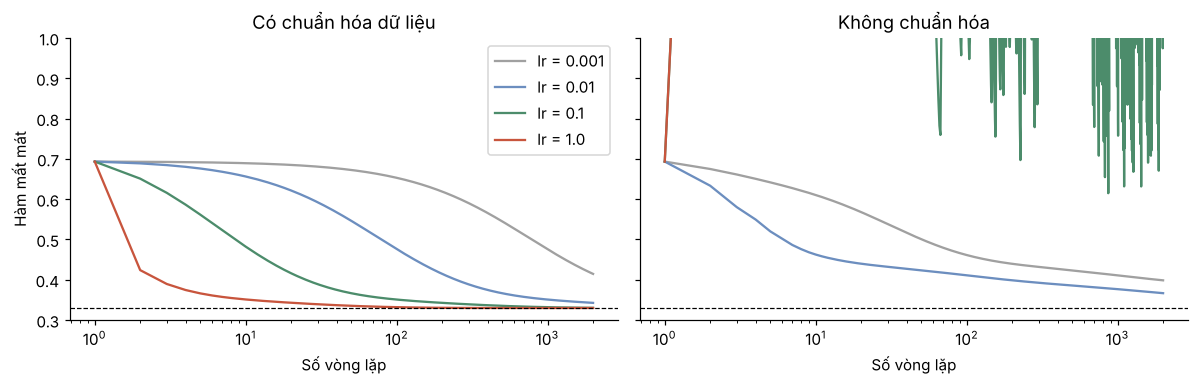

In [3]:
ket_qua, duong_loss = [], {}
for chuan_hoa in [True, False]:
    Xa, Xb = chuan_bi(COMPACT, chuan_hoa)
    for lr in [0.001, 0.01, 0.1, 1.0]:
        w_, b_, h = huan_luyen_gd(Xa, ytr, lr, so_vong=2000)
        ok = bool(np.isfinite(h[-1]))
        gan_day = np.where(h <= loss_toi_uu + 1e-3)[0]
        ket_qua.append({"chuẩn hóa": "có" if chuan_hoa else "không", "tốc độ học": lr,
                        "loss sau 2000 vòng": h[-1],
                        "vòng tới gần đáy": int(gan_day[0]) + 1 if len(gan_day) else "chưa tới",
                        "số lần loss tăng": int(np.sum(np.diff(h) > 1e-9)),
                        "accuracy test": accuracy_score(yte, sigmoid(Xb @ w_ + b_) >= 0.5) if ok else np.nan})
        duong_loss[(chuan_hoa, lr)] = h
display(pd.DataFrame(ket_qua).round(4))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for a, ch, tieu_de in zip(ax, [True, False], ["Có chuẩn hóa dữ liệu", "Không chuẩn hóa"]):
    for lr, mau in zip([0.001, 0.01, 0.1, 1.0], ["#A0A0A0", "#6C8EBF", "#4C8C6B", "#C8553D"]):
        h = duong_loss[(ch, lr)]
        a.plot(np.arange(1, len(h) + 1), np.minimum(h, 3), color=mau, label=f"lr = {lr}")
    a.axhline(loss_toi_uu, ls="--", color="k", lw=0.8)
    a.set_xscale("log"); a.set_title(tieu_de); a.set_xlabel("Số vòng lặp")
ax[0].set_ylabel("Hàm mất mát"); ax[0].set_ylim(0.3, 1.0); ax[0].legend()
plt.tight_layout(); plt.show()

## Đọc kết quả
1. **Có chuẩn hóa:** tốc độ học càng lớn càng nhanh. lr = 1,0 chỉ cần khoảng 145 vòng để tới sát đáy; lr = 0,1 cần khoảng 1.400 vòng; 0,01 và 0,001 sau 2.000 vòng vẫn chưa tới. Mất mát luôn giảm đều (không lần nào tăng), đúng như lý thuyết cho hàm lồi.
2. **Không chuẩn hóa:** cùng tốc độ học cho kết quả tệ hơn nhiều. lr = 0,1 làm mất mát nhảy lên xuống hàng trăm lần; lr = 1,0 **phân kỳ** (mất mát vọt lên gần 10 và độ chính xác tụt còn khoảng 74%).
3. **Vì sao?** Ở Bước 2 ta đã tính: không chuẩn hóa thì tốc độ học an toàn tối đa chỉ cỡ 0,009, nên 0,1 và 1,0 đều vượt ngưỡng. Có chuẩn hóa thì ngưỡng là khoảng 2, nên 1,0 vẫn ổn. **Lý thuyết và thực nghiệm khớp nhau.**
4. Khi đã hội tụ, các cấu hình cho chất lượng gần như nhau: tốc độ học quyết định *có tới được đáy không và nhanh đến đâu*, chứ không đổi vị trí đáy.
5. Bản tự cài khớp thư viện đến cỡ 0,0005: công thức gradient ở trên được cài đúng.

**Lưu ý riêng cho đề tài.** TabICLv2 không huấn luyện lại trên dữ liệu của mình (nó đã được huấn luyện một lần, với bộ tối ưu Muon, trên dữ liệu giả lập). Vì vậy thí nghiệm tốc độ học làm trên Hồi quy Logistic. Hãy nói thẳng điều này với thầy.

## Thầy có thể hỏi
- *Tốc độ học quá lớn thì sao?* Bước nhảy qua đáy rồi sang sườn bên kia; nếu vượt ngưỡng 2/L thì càng nhảy càng cao và phân kỳ.
- *Vì sao hàm này chỉ có một đáy?* Cross-entropy của Hồi quy Logistic là hàm lồi theo tham số. Mạng sâu như Transformer thì không lồi.
- *Tiêu chuẩn dừng là gì?* Mất mát gần như không đổi giữa hai vòng liên tiếp, hoặc đạt số vòng tối đa.